In [4]:
import os.path
import itertools
from random import randint
import numpy as np
import matplotlib.pyplot as plt

from sklearn.utils import shuffle
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import confusion_matrix

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.models import Sequential, load_model, model_from_json
from tensorflow.keras.layers import Dense
from tensorflow.keras.optimizers import Adam

I0000 00:00:1793560126.877432   11865 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793560127.097415   11865 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793560128.529939   11865 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


In [5]:
train_labels = []
train_samples = []

for i in range(50):
    random_young = randint(13, 64)
    train_samples.append(random_young)
    train_labels.append(1)

    random_older = randint(65, 100)
    train_samples.append(random_older)
    train_labels.append(0)

for i in range(1000):
    random_young = randint(13, 64)
    train_samples.append(random_young)
    train_labels.append(0)

    random_older = randint(65, 100)
    train_samples.append(random_older)
    train_labels.append(1)

In [6]:
train_labels = np.array(train_labels)
train_samples = np.array(train_samples)
train_labels, train_samples = shuffle(train_labels, train_samples)

scaler = MinMaxScaler(feature_range=(0, 1))
scaled_train_samples = scaler.fit_transform(train_samples.reshape(-1, 1))

In [7]:
model = Sequential([
    Dense(units=16, input_shape=(1,), activation='relu'),
    Dense(units=32, activation='relu'),
    Dense(units=2, activation='softmax')
])

model.summary()

/home/marat/tf_project/venv/lib/python3.14/site-packages/keras/src/layers/core/dense.py:100: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
W0000 00:00:1793560408.576480   11865 gpu_device.cc:2453] TensorFlow was not built with CUDA kernel binaries compatible with compute capability 12.0a. CUDA kernels will be jit-compiled from PTX, which could take 30 minutes or longer.
W0000 00:00:1793560408.579033   11865 gpu_device.cc:2453] TensorFlow was not built with CUDA kernel binaries compatible with compute capability 12.0a. CUDA kernels will be jit-compiled from PTX, which could take 30 minutes or longer.
I0000 00:00:1793560408.736926   11865 gpu_device.cc:2036] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 9217 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 5070

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │            32 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │           544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 2)              │            66 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 642 (2.51 KB)

 Trainable params: 642 (2.51 KB)

 Non-trainable params: 0 (0.00 B)

In [8]:
model.compile(
    optimizer=Adam(learning_rate=0.0001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.fit(
    x=scaled_train_samples,
    y=train_labels,
    validation_split=0.1,  
    batch_size=10,
    epochs=30,
    shuffle=True,
    verbose=2
)

Epoch 1/30


I0000 00:00:1793560614.128436   11865 service.cc:154] XLA service 0x45d6b770 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1793560614.128473   11865 service.cc:170]   StreamExecutor [0]: NVIDIA GeForce RTX 5070, Compute Capability 12.0a (Driver: 13.5.0[621.1.0]; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.27.0)
I0000 00:00:1793560614.177147   11865 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1793560620.629368   11865 cuda_dnn.cc:442] Loaded cuDNN version 92700
I0000 00:00:1793560620.745982   11865 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


189/189 - 8s - 41ms/step - accuracy: 0.5016 - loss: 0.6844 - val_accuracy: 0.5143 - val_loss: 0.6676
Epoch 2/30
189/189 - 0s - 2ms/step - accuracy: 0.5487 - loss: 0.6556 - val_accuracy: 0.5762 - val_loss: 0.6402
Epoch 3/30
189/189 - 0s - 2ms/step - accuracy: 0.6095 - loss: 0.6305 - val_accuracy: 0.6571 - val_loss: 0.6130
Epoch 4/30
189/189 - 0s - 2ms/step - accuracy: 0.6640 - loss: 0.6044 - val_accuracy: 0.7095 - val_loss: 0.5833
Epoch 5/30
189/189 - 0s - 2ms/step - accuracy: 0.7153 - loss: 0.5774 - val_accuracy: 0.7524 - val_loss: 0.5570
Epoch 6/30
189/189 - 0s - 2ms/step - accuracy: 0.7529 - loss: 0.5533 - val_accuracy: 0.7905 - val_loss: 0.5319
Epoch 7/30
189/189 - 0s - 2ms/step - accuracy: 0.7730 - loss: 0.5298 - val_accuracy: 0.8429 - val_loss: 0.5074
Epoch 8/30
189/189 - 0s - 2ms/step - accuracy: 0.7926 - loss: 0.5069 - val_accuracy: 0.8571 - val_loss: 0.4835
Epoch 9/30
189/189 - 0s - 2ms/step - accuracy: 0.8153 - loss: 0.4843 - val_accuracy: 0.8714 - val_loss: 0.4604
Epoch 10/30

In [9]:
test_labels = []
test_samples = []

for i in range(10):
    random_young = randint(13, 64)
    test_samples.append(random_young)
    test_labels.append(1)

    random_older = randint(65, 100)
    test_samples.append(random_older)
    test_labels.append(0)

for i in range(200):
    random_young = randint(13, 64)
    test_samples.append(random_young)
    test_labels.append(0)

    random_older = randint(65, 100)
    test_samples.append(random_older)
    test_labels.append(1)

test_labels = np.array(test_labels)
test_samples = np.array(test_samples)
test_labels, test_samples = shuffle(test_labels, test_samples)

scaled_test_samples = scaler.transform(test_samples.reshape(-1, 1))

predictions = model.predict(x=scaled_test_samples, batch_size=10, verbose=0)
rounded_predictions = np.argmax(predictions, axis=-1)

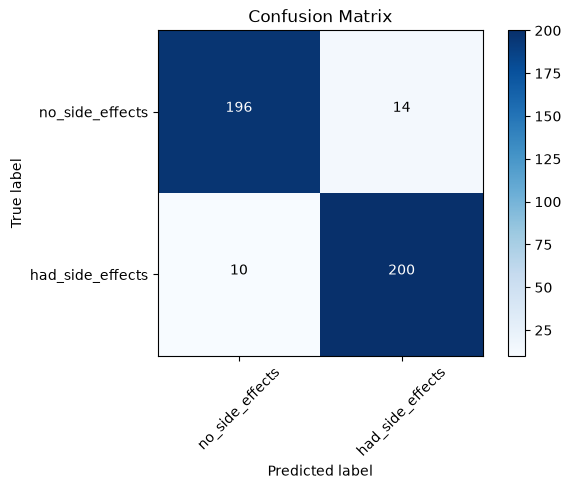

In [10]:
%matplotlib inline

cm = confusion_matrix(y_true=test_labels, y_pred=rounded_predictions)

def plot_confusion_matrix(cm, classes, normalize=False, title='Confusion matrix', cmap=plt.cm.Blues):
    plt.imshow(cm, interpolation='nearest', cmap=cmap)
    plt.title(title)
    plt.colorbar()
    tick_marks = np.arange(len(classes))
    plt.xticks(tick_marks, classes, rotation=45)
    plt.yticks(tick_marks, classes)

    if normalize:
        cm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

    thresh = cm.max() / 2.
    for i, j in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
        plt.text(j, i, cm[i, j],
                 horizontalalignment="center",
                 color="white" if cm[i, j] > thresh else "black")

    plt.tight_layout()
    plt.ylabel('True label')
    plt.xlabel('Predicted label')

cm_plot_labels = ['no_side_effects', 'had_side_effects']
plot_confusion_matrix(cm=cm, classes=cm_plot_labels, title='Confusion Matrix')

In [11]:
os.makedirs('models', exist_ok=True)
if not os.path.isfile('models/medical_trial_model.h5'):
    model.save('models/medical_trial_model.h5')

new_model = load_model('models/medical_trial_model.h5')